Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

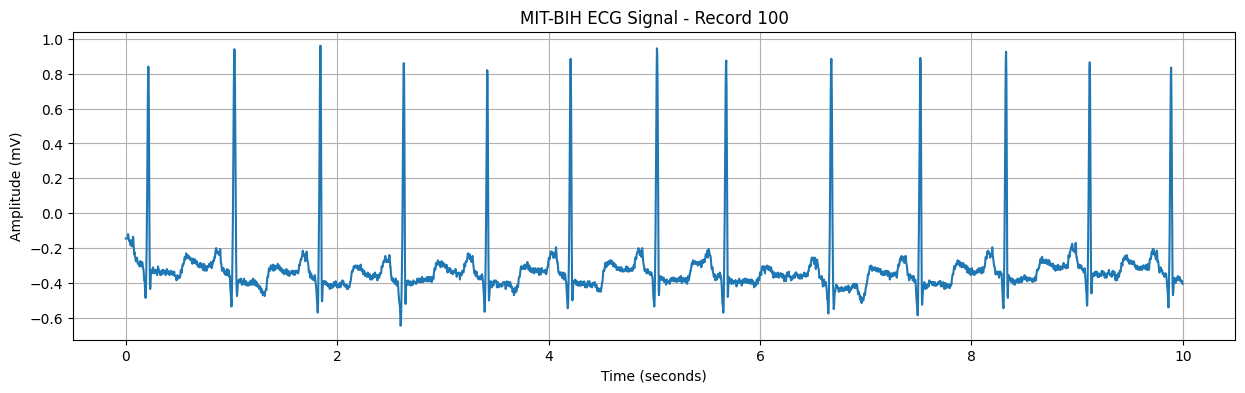

  Class  Count
0     N  90125
1     S   2781
2     V   7009
3     F    803
4     Q     15


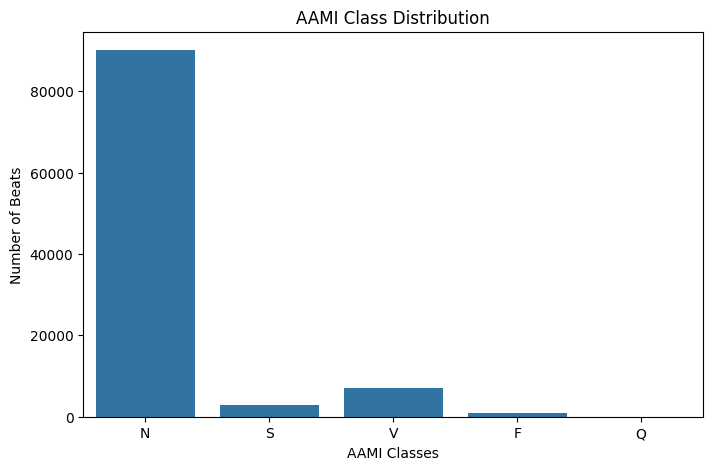

In [2]:

!pip install -q wfdb

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
import tensorflow as tf

from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

np.random.seed(42)
tf.random.set_seed(42)

DATA_DIR = "/content/mitdb"
os.makedirs(DATA_DIR, exist_ok=True)

FS = 360
BEAT_LENGTH = 256
LEFT = 90
RIGHT = 166

CLASS_NAMES = ["N", "S", "V", "F", "Q"]

CLASS_MAP = {
    "N": 0, "L": 0, "R": 0, "e": 0, "j": 0,
    "A": 1, "a": 1, "J": 1, "S": 1,
    "V": 2, "E": 2,
    "F": 3,
    "/": 4, "f": 4, "Q": 4
}

PACED_RECORDS = {"102", "104", "107", "217"}

records = wfdb.get_record_list("mitdb")

wfdb.dl_database(
    "mitdb",
    dl_dir=DATA_DIR,
    records=records
)

print("Total records:", len(records))

record = wfdb.rdrecord(os.path.join(DATA_DIR, "100"))

lead_names = [name.upper() for name in record.sig_name]

lead = lead_names.index("MLII") if "MLII" in lead_names else (
    lead_names.index("II") if "II" in lead_names else 0
)

ecg = record.p_signal[:, lead]

plt.figure(figsize=(15, 4))
plt.plot(np.arange(min(len(ecg), 3600)) / FS, ecg[:3600])
plt.title("MIT-BIH ECG Signal - Record 100")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid()
plt.show()

class_counts = {name: 0 for name in CLASS_NAMES}

for record_name in records:

    if record_name in PACED_RECORDS:
        continue

    try:
        ann = wfdb.rdann(
            os.path.join(DATA_DIR, record_name),
            "atr"
        )

        for symbol in ann.symbol:
            if symbol in CLASS_MAP:
                class_counts[CLASS_NAMES[CLASS_MAP[symbol]]] += 1

    except Exception as e:
        print("Skipped:", record_name, e)

distribution = pd.DataFrame({
    "Class": list(class_counts.keys()),
    "Count": list(class_counts.values())
})

print(distribution)

plt.figure(figsize=(8, 5))
sns.barplot(data=distribution, x="Class", y="Count")
plt.title("AAMI Class Distribution")
plt.xlabel("AAMI Classes")
plt.ylabel("Number of Beats")
plt.show()


Dataset shape: (100694, 256)
Labels shape: (100694,)


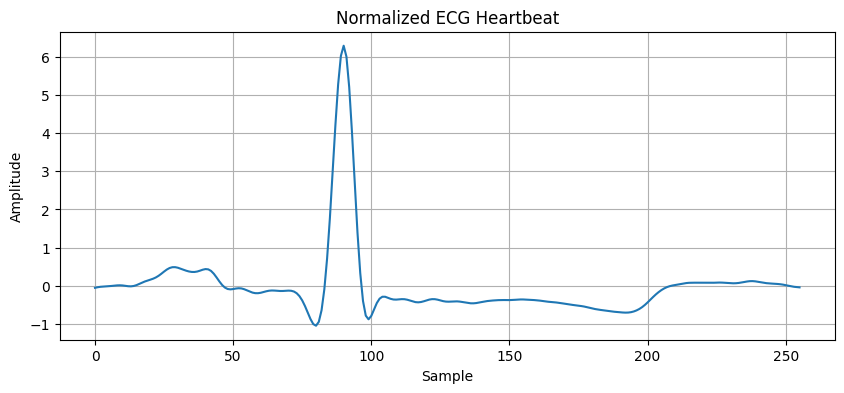

Training: (64602, 256, 1)
Validation: (15901, 256, 1)
Testing: (20191, 256, 1)
Class weights: {0: 0.2227693580923809, 1: 5.786117330944917, 2: 3.266026289180991, 3: 32.060545905707194, 4: 1174.581818181818}


In [3]:

def filter_ecg(signal, fs=360):

    sos = butter(
        4,
        [0.5, 40],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    return sosfiltfilt(sos, signal)


X_data = []
y_data = []
groups = []

for record_name in records:

    if record_name in PACED_RECORDS:
        continue

    try:
        rec = wfdb.rdrecord(
            os.path.join(DATA_DIR, record_name)
        )

        lead_names = [name.upper() for name in rec.sig_name]

        if "MLII" in lead_names:
            lead = lead_names.index("MLII")
        elif "II" in lead_names:
            lead = lead_names.index("II")
        else:
            lead = 0

        ecg = np.nan_to_num(rec.p_signal[:, lead])
        ecg = filter_ecg(ecg, rec.fs)

        ann = wfdb.rdann(
            os.path.join(DATA_DIR, record_name),
            "atr"
        )

        for sample, symbol in zip(ann.sample, ann.symbol):

            if symbol not in CLASS_MAP:
                continue

            start = sample - LEFT
            end = sample + RIGHT

            if start < 0 or end > len(ecg):
                continue

            beat = ecg[start:end].copy()

            if len(beat) != BEAT_LENGTH:
                continue

            beat = (beat - np.mean(beat)) / (np.std(beat) + 1e-8)

            X_data.append(beat)
            y_data.append(CLASS_MAP[symbol])
            groups.append(record_name)

    except Exception as e:
        print("Error processing", record_name, e)

X = np.asarray(X_data, dtype=np.float32)
y = np.asarray(y_data, dtype=np.int32)
groups = np.asarray(groups)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)

plt.figure(figsize=(10, 4))
plt.plot(X[0])
plt.title("Normalized ECG Heartbeat")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(X, y, groups)
)

X_train_val = X[train_val_idx]
y_train_val = y[train_val_idx]
groups_train_val = groups[train_val_idx]

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    split2.split(X_train_val, y_train_val, groups_train_val)
)

X_train = X_train_val[train_idx]
y_train = y_train_val[train_idx]

X_val = X_train_val[val_idx]
y_val = y_train_val[val_idx]

X_test = X[test_idx]
y_test = y[test_idx]

X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(c): float(w)
    for c, w in zip(classes, weights)
}

print("Class weights:", class_weights)



Training: RNN
Epoch 1/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - accuracy: 0.2260 - loss: 1.6024 - val_accuracy: 0.4222 - val_loss: 1.4027 - learning_rate: 0.0010
Epoch 2/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.1768 - loss: 1.4853 - val_accuracy: 0.0840 - val_loss: 1.5080 - learning_rate: 0.0010
Epoch 3/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.1331 - loss: 1.5217 - val_accuracy: 0.0109 - val_loss: 1.6016 - learning_rate: 0.0010
Epoch 4/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.1675 - loss: 1.6323 - val_accuracy: 0.3675 - val_loss: 1.5327 - learning_rate: 5.0000e-04
Epoch 5/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.2129 - loss: 1.5340 - val_accuracy: 0.2580 - val_loss: 1.4956 - learning_rate: 5.0000e-04

Classification Report: RNN
              precision    recall  f1-score   support

           N       0.93      0.34      0.50     18291
           S       0.03      0.27      0.05       490
           V       0

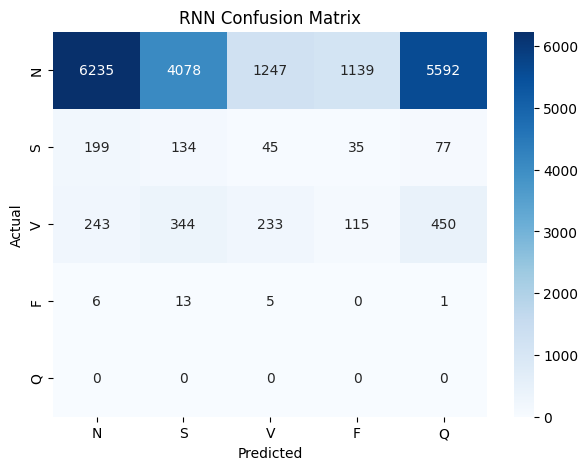


Training: LSTM
Epoch 1/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.0802 - loss: 1.6042 - val_accuracy: 0.0365 - val_loss: 1.4354 - learning_rate: 0.0010
Epoch 2/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.1465 - loss: 1.4290 - val_accuracy: 0.0349 - val_loss: 1.4939 - learning_rate: 0.0010
Epoch 3/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.1638 - loss: 1.3507 - val_accuracy: 0.0776 - val_loss: 1.5064 - learning_rate: 0.0010
Epoch 4/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.1818 - loss: 1.2303 - val_accuracy: 0.5024 - val_loss: 1.4207 - learning_rate: 5.0000e-04
Epoch 5/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.3303 - loss: 1.1476 - val_accuracy: 0.6598 - val_loss: 1.3573 - learning_rate: 5.0000e-04
Epoch 6/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.3927 - loss: 1.2330 - val_accuracy: 0.5953 - val_loss: 1.4066 - learning_rate: 5.0000e-04
Epoch 7/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step -

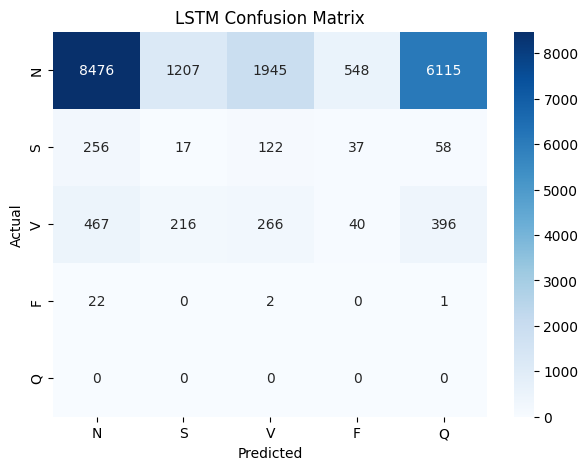


Training: GRU
Epoch 1/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.1942 - loss: 1.6274 - val_accuracy: 0.0749 - val_loss: 1.5777 - learning_rate: 0.0010
Epoch 2/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.0819 - loss: 1.5595 - val_accuracy: 0.0972 - val_loss: 1.5456 - learning_rate: 0.0010
Epoch 3/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.1078 - loss: 1.4400 - val_accuracy: 0.0824 - val_loss: 1.5810 - learning_rate: 0.0010
Epoch 4/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.1173 - loss: 1.3853 - val_accuracy: 0.0903 - val_loss: 1.5483 - learning_rate: 0.0010
Epoch 5/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.1489 - loss: 1.1849 - val_accuracy: 0.1062 - val_loss: 1.4803 - learning_rate: 5.0000e-04
Epoch 6/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.1762 - loss: 1.1616 - val_accuracy: 0.1507 - val_loss: 1.4032 - learning_rate: 5.0000e-04
Epoch 7/20
253/253 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accu

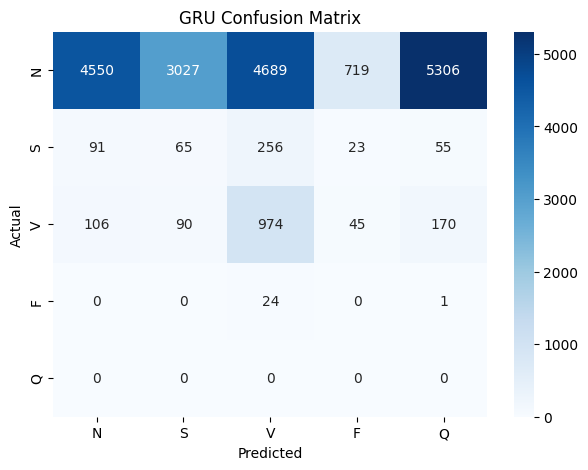


Model Performance Comparison
      Accuracy  Precision  Recall  F1-score
RNN     0.3270     0.2229  0.1565    0.1424
LSTM    0.4338     0.2090  0.1380    0.1554
GRU     0.2768     0.2286  0.2169    0.1392


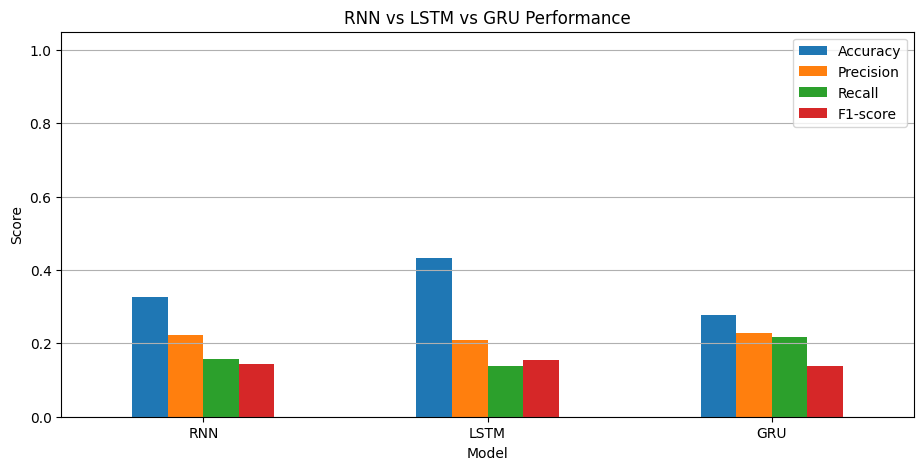

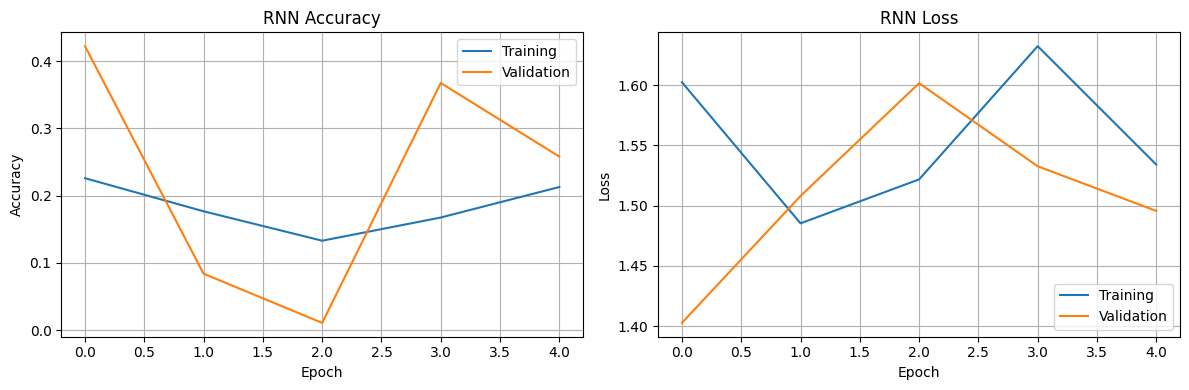

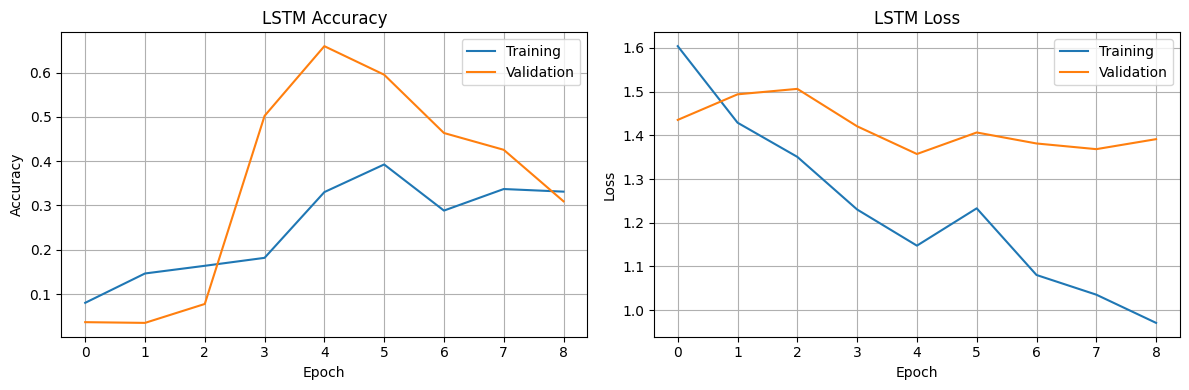

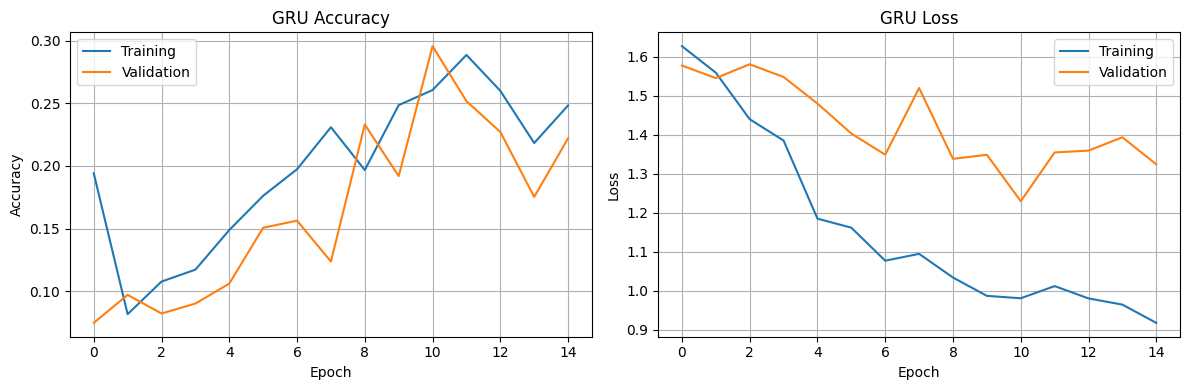


Model: RNN
Total test beats: 20191
Incorrect predictions: 13589
Actual  Predicted
N       Q            5592
        S            4078
        V            1247
        F            1139
V       Q             450
        S             344
        N             243
S       N             199
V       F             115
S       Q              77
Name: count, dtype: int64

Model: LSTM
Total test beats: 20191
Incorrect predictions: 11432
Actual  Predicted
N       Q            6115
        V            1945
        S            1207
        F             548
V       N             467
        Q             396
S       N             256
V       S             216
S       V             122
        Q              58
Name: count, dtype: int64

Model: GRU
Total test beats: 20191
Incorrect predictions: 14602
Actual  Predicted
N       Q            5306
        V            4689
        S            3027
        F             719
S       V             256
V       Q             170
        N             

In [4]:

def build_model(model_type):

    model = Sequential([
        Input(shape=(BEAT_LENGTH, 1))
    ])

    if model_type == "RNN":
        model.add(SimpleRNN(64, activation="tanh"))

    elif model_type == "LSTM":
        model.add(LSTM(64, activation="tanh"))

    elif model_type == "GRU":
        model.add(GRU(64, activation="tanh"))

    model.add(Dropout(0.3))
    model.add(Dense(32, activation="relu"))
    model.add(Dropout(0.2))
    model.add(Dense(5, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


models = {}
histories = {}
results = {}

for name in ["RNN", "LSTM", "GRU"]:

    print("\nTraining:", name)

    tf.keras.backend.clear_session()

    model = build_model(name)

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        patience=2,
        factor=0.5,
        min_lr=1e-6
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=256,
        class_weight=class_weights,
        callbacks=[early_stopping, reduce_lr],
        verbose=1
    )

    models[name] = model
    histories[name] = history

    y_prob = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_test, y_pred, average="macro", zero_division=0)
    }

    print("\nClassification Report:", name)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1, 2, 3, 4]
    )

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


comparison = pd.DataFrame(results).T

print("\nModel Performance Comparison")
print(comparison.round(4))

comparison.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("RNN vs LSTM vs GRU Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

for name, history in histories.items():

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Training")
    plt.plot(history.history["val_accuracy"], label="Validation")
    plt.title(name + " Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Training")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.title(name + " Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()

for name, model in models.items():

    y_pred = np.argmax(
        model.predict(X_test, verbose=0),
        axis=1
    )

    errors = np.where(y_pred != y_test)[0]

    print("\nModel:", name)
    print("Total test beats:", len(y_test))
    print("Incorrect predictions:", len(errors))

    if len(errors) > 0:
        error_df = pd.DataFrame({
            "Actual": [CLASS_NAMES[y_test[i]] for i in errors],
            "Predicted": [CLASS_NAMES[y_pred[i]] for i in errors]
        })

        print(error_df.value_counts().head(10))

os.makedirs("/content/mitbih_models", exist_ok=True)

for name, model in models.items():
    model.save(f"/content/mitbih_models/{name.lower()}_model.keras")

import shutil

shutil.make_archive(
    "/content/mitbih_models",
    "zip",
    "/content/mitbih_models"
)

print("\nModel performance:")
print(comparison.round(4))

print("\nBest model:", comparison["F1-score"].idxmax())
